<a href="https://colab.research.google.com/github/vtu27065/Deep-Learning/blob/main/Task_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
import torchvision
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np

#Step 2 — Define image preprocessing
ResNet18 expects larger images, so we resize CIFAR-10 images from 32×32 to 224×224.

In [2]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

#Step 4 — Download CIFAR-10

This automatically downloads the predefined dataset

In [3]:
train_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))

100%|██████████| 170M/170M [42:41<00:00, 66.6kB/s]


Training images: 50000
Testing images: 10000


#Step 5 — Create DataLoaders

In [4]:
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=2
)

#Step 6 — Check the classes

In [5]:
classes = train_dataset.classes

print(classes)

['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


#Step 7 — Load the pretrained ResNet18

This is the Transfer Learning part.

In [13]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = models.resnet18(weights="DEFAULT")

model = model.to(device)

print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

#Step 8 — Freeze the pretrained layers

In [8]:
for param in model.parameters():
    param.requires_grad = False

#Step 9 — Replace the final classification layer

Original ResNet18 was designed for 1000 ImageNet classes.

Our CIFAR-10 dataset has 10 classes.

In [9]:
num_classes = 10

model.fc = nn.Linear(
    model.fc.in_features,
    num_classes
)

model = model.to(device)

#Now the model becomes:

Pre-trained ResNet18 → 10-class classifier

#Step 10 — Define loss function and optimizer

Since CIFAR-10 is a multi-class classification problem, we use:

Cross Entropy Loss

In [10]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.fc.parameters(),
    lr=0.001
)

#Notice that we are optimizing only the new final layer, because the earlier layers are frozen.

#Step 11 — Train the model

For the first experiment, use only 5 epochs so that it finishes reasonably quickly.

In [11]:
num_epochs = 5

train_losses = []
train_accuracies = []

for epoch in range(num_epochs):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(train_loader)
    epoch_accuracy = 100 * correct / total

    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Loss: {epoch_loss:.4f} "
        f"Accuracy: {epoch_accuracy:.2f}%"
    )

Epoch [1/5] Loss: 0.8363 Accuracy: 73.18%
Epoch [2/5] Loss: 0.6178 Accuracy: 78.81%
Epoch [3/5] Loss: 0.5878 Accuracy: 79.67%
Epoch [4/5] Loss: 0.5765 Accuracy: 80.12%
Epoch [5/5] Loss: 0.5650 Accuracy: 80.49%


#Step 12 — Test the model

In [12]:
model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

test_accuracy = 100 * correct / total

print(f"Test Accuracy: {test_accuracy:.2f}%")

Test Accuracy: 80.26%


#Step 13 — Plot training loss

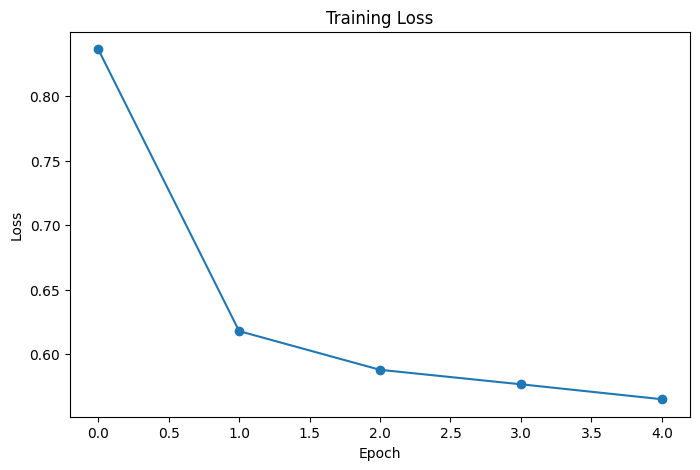

In [14]:
plt.figure(figsize=(8,5))

plt.plot(train_losses, marker='o')

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")

plt.show()

#Step 14 — Plot training accuracy

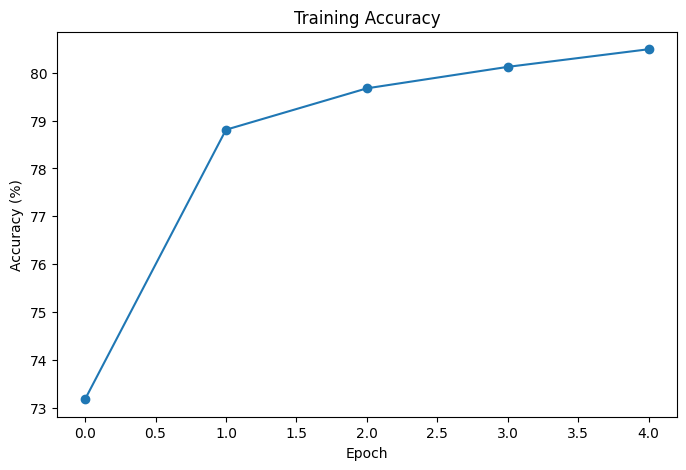

In [15]:
plt.figure(figsize=(8,5))

plt.plot(train_accuracies, marker='o')

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training Accuracy")

plt.show()

#Step 15 — Display some predictions

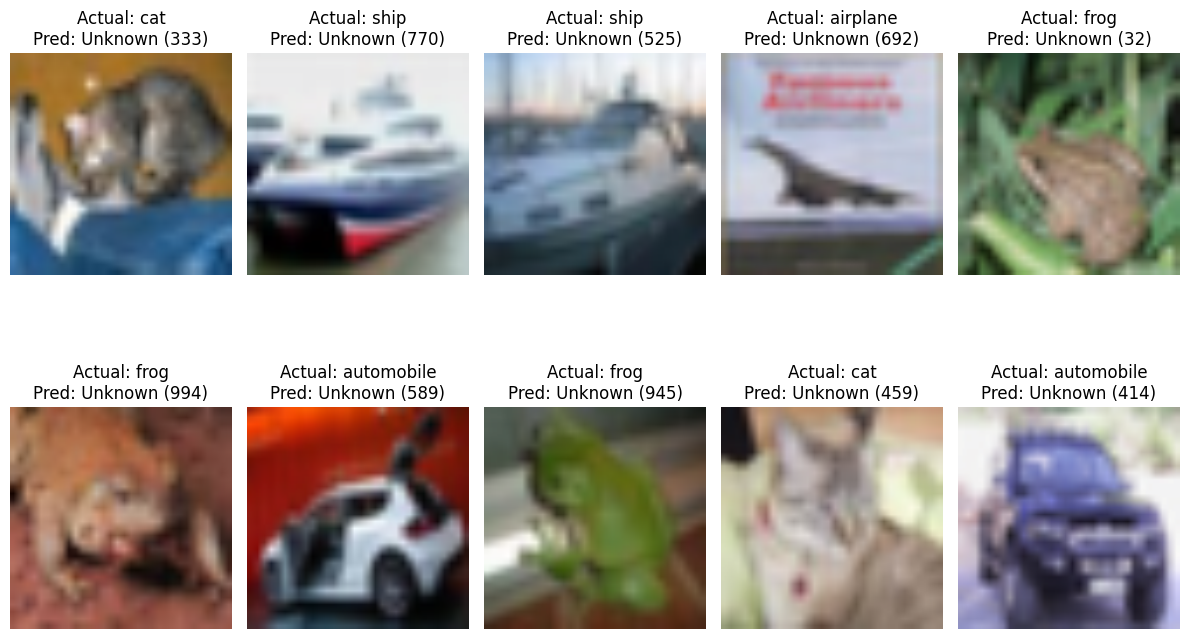

In [18]:
images, labels = next(iter(test_loader))

images = images.to(device)

with torch.no_grad():
    outputs = model(images)

_, predictions = torch.max(outputs, 1)

plt.figure(figsize=(12, 8))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    image = images[i].cpu().numpy()
    image = np.transpose(image, (1, 2, 0))

    # Undo normalization for display
    image = image * np.array([0.229, 0.224, 0.225])
    image = image + np.array([0.485, 0.456, 0.406])
    image = np.clip(image, 0, 1)

    plt.imshow(image)

    # Safe guard indices
    pred_idx = predictions[i].item()
    actual_idx = labels[i].item()

    pred_class = classes[pred_idx] if pred_idx < len(classes) else f"Unknown ({pred_idx})"
    actual_class = classes[actual_idx] if actual_idx < len(classes) else f"Unknown ({actual_idx})"

    plt.title(
        f"Actual: {actual_class}\n"
        f"Pred: {pred_class}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()